# Measuring a drug-induced interaction

Does a small molecule bring two proteins together?

The bait is CRBN, substrate receptor of a CUL4 E3 ligase, fused to TadA8e.
The prey library is 90 zinc-finger domains on MCP.
Pomalidomide binds CRBN and remodels the surface it presents, so a domain carrying the right degron becomes a neosubstrate.
For most of these domains the interaction does not exist without the drug.

This vignette fits PyroPPI to the screen, ranks the 90 domains, and checks the ranking against two published measurements of pomalidomide-induced degradation.
With no untreated arm there is no pair baseline, so the fit reports the whole propensity under the drug.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

import pyroppi

# The repository root is the nearest directory above us that holds the datasets,
# so the notebook runs from its own directory or from the repository root.
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "zf_pom").is_dir())
DATA = REPO / "data"

# Okabe-Ito, the colourblind-safe palette the manuscript figures use.
BLUE = "#0072B2"        # the 300 nM arm
VERMILLION = "#D55E00"  # the 3 uM arm, and the known degradation targets
GREY = "#6F6F6F"
PALE = "#D9D9D9"

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
    "font.size": 8,
    "axes.titlesize": 9,
    "axes.labelsize": 8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "legend.frameon": False,
    "figure.dpi": 110,
})

## The data

`counts.csv` has one row per sample and measured pair: bait, prey, reporter reads, and how many were edited.
`samples.csv` has one row per sample, with descriptive columns followed by the 0/1 indicators the design is built from.

In [2]:
counts, samples = pyroppi.read_dataset(DATA / "zf_pom")
print(f"{len(counts)} observations, {len(samples)} samples, "
      f"{counts['prey'].nunique()} zinc-finger domains")
counts.head()

720 observations, 8 samples, 90 zinc-finger domains


,sample,bait,prey,total,edited
0,POM_3_UM_1,CRBN,E4F1,7823,75
1,POM_3_UM_1,CRBN,IKZF3,31170,1110
2,POM_3_UM_1,CRBN,PATZ1,6810,52
3,POM_3_UM_1,CRBN,TREF1,14146,141
4,POM_3_UM_1,CRBN,VEZF1,15491,127


In [3]:
samples

,sample,treatment,replicate,POM_300_NM,POM_3_UM
0,POM_3_UM_1,pomalidomide_3uM,1,0,1
1,POM_3_UM_2,pomalidomide_3uM,2,0,1
2,POM_3_UM_3,pomalidomide_3uM,3,0,1
3,POM_3_UM_4,pomalidomide_3uM,4,0,1
4,POM_300_NM_1,pomalidomide_300nM,1,1,0
5,POM_300_NM_2,pomalidomide_300nM,2,1,0
6,POM_300_NM_3,pomalidomide_300nM,3,1,0
7,POM_300_NM_4,pomalidomide_300nM,4,1,0


## Every sample is drug-treated

Eight samples: 300 nM and 3 µM pomalidomide, four replicates each.
The experiment ran a DMSO arm too, but it is not in this fit's input, so no untreated sample exists here.
Each sample has exactly one dose indicator switched on.

The median observation carries about 21,000 reporter reads, and one of 720 falls below the 20-read floor `pyroppi.fit` censors by default.

In [4]:
DRUG = ["POM_300_NM", "POM_3_UM"]

print("dose indicators switched on per sample:")
print(samples[DRUG].sum(axis=1).value_counts().to_string())
print()
print(f"median reporter reads per observation: {counts['total'].median():,.0f}")
print(f"observations below the 20-read floor:  {(counts['total'] < 20).sum()}")

dose indicators switched on per sample:
1    8

median reporter reads per observation: 21,430
observations below the 20-read floor:  1


Below: the observed edited fraction of every domain in every sample, then the four replicates of each arm pooled and the two doses put against each other.
Reads are pooled rather than averaging per-replicate fractions, because the pooled fraction is what a binomial likelihood sees.

32 of 90 domains sit above the diagonal, so the higher dose does not raise editing everywhere.
The difference is concentrated in the domains that edit most.

In [5]:
def observed_by_dose(counts, samples):
    """Edited fraction of each domain in each arm, reads pooled over replicates."""
    table = counts.merge(samples[["sample", "treatment"]], on="sample")
    totals = table.groupby(["prey", "treatment"])[["total", "edited"]].sum()
    return (totals["edited"] / totals["total"]).unstack()


wide = observed_by_dose(counts, samples)
higher = (wide["pomalidomide_3uM"] > wide["pomalidomide_300nM"]).sum()
print(f"domains edited more at 3 uM than at 300 nM: {higher} of {len(wide)}")

domains edited more at 3 uM than at 300 nM: 32 of 90


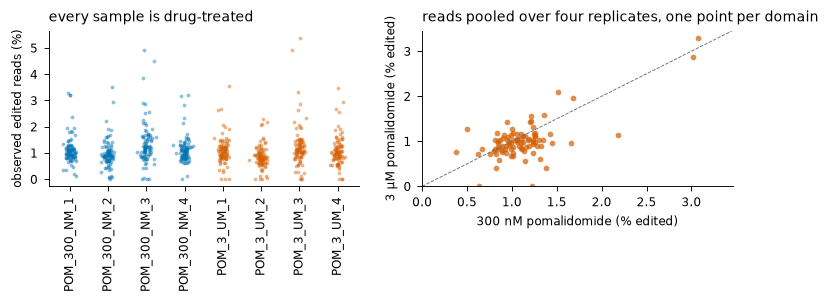

In [6]:
fig, (left, right) = plt.subplots(1, 2, figsize=(6.8, 2.8))

order = list(samples.sort_values(["treatment", "replicate"])["sample"])
fraction = counts["edited"] / counts["total"]
rng = np.random.default_rng(0)
for x, name in enumerate(order):
    rows = counts["sample"] == name
    jitter = rng.normal(0, 0.08, int(rows.sum()))
    colour = BLUE if "300" in name else VERMILLION
    left.scatter(x + jitter, fraction[rows] * 100, s=6, color=colour, alpha=0.45, lw=0)
left.set_xticks(range(len(order)), order, rotation=90)
left.set_ylabel("observed edited reads (%)")
left.set_title("every sample is drug-treated", loc="left")

low, high = wide["pomalidomide_300nM"] * 100, wide["pomalidomide_3uM"] * 100
span = [0, max(low.max(), high.max()) * 1.05]
right.plot(span, span, color=GREY, lw=0.6, ls="--")
right.scatter(low, high, s=14, color=VERMILLION, alpha=0.7, lw=0)
right.set_xlim(span)
right.set_ylim(span)
right.set_xlabel("300 nM pomalidomide (% edited)")
right.set_ylabel("3 µM pomalidomide (% edited)")
right.set_title("reads pooled over four replicates, one point per domain", loc="left")

fig.tight_layout()

## Fitting without a pair baseline

PyroPPI sums three blocks on the log-odds scale: a per-pair baseline, drug or condition shifts, and cell-type shifts.
The baseline is the interaction in the reference condition; the drug term is what treatment adds.

That split needs a reference condition.
Every observation here is drug-treated, so for any pair the baseline and the drug shift are always on together and only their sum enters the likelihood.
Any constant could move between them without changing a fitted probability.
Shrinking both toward their priors would decide the split arbitrarily and then report it as a measurement.

So the fit drops the pair block with `baseline=False` and estimates the drug block alone.
The quantity this screen reports is the whole fitted editing propensity under pomalidomide, with no untreated baseline to subtract.

`baseline=False` requires drug or cell columns, which this fit has.

In [7]:
start = time.perf_counter()
fit = pyroppi.fit(counts, samples, drug=DRUG, baseline=False, num_steps=60_000)
runtime = time.perf_counter() - start

print(f"fitted in {runtime:.0f} s on CPU")
print(f"{len(fit.canonical)} canonical pairs, final ELBO loss {fit.losses[-1]:,.0f}")

Fitting:   0%|          | 0/60000 [00:00<?, ?it/s]

fitted in 86 s on CPU
90 canonical pairs, final ELBO loss 9,162


A baseline-free fit has no pair table. `Fit.pairs()` raises instead of returning zeros that would
read as measurements, so read `Fit.effects()`.

In [8]:
try:
    fit.pairs()
except ValueError as error:
    print(f"ValueError: {error}")

fit.effects().head()

ValueError: this fit has no pair baseline; use effects() instead


,block,covariate,protein_a,protein_b,logit_mean,logit_sd
0,drug,POM_300_NM,CRBN,E4F1,-4.791061,0.045931
1,drug,POM_300_NM,CRBN,IKZF3,-3.456285,0.013078
2,drug,POM_300_NM,CRBN,PATZ1,-4.383223,0.038954
3,drug,POM_300_NM,CRBN,TREF1,-4.244402,0.025520
4,drug,POM_300_NM,CRBN,VEZF1,-4.678501,0.031318


## The drug block as a propensity

`effects()` gives one row per covariate and canonical pair on the log-odds scale.
The canonical pair is always CRBN and one domain, so the domain is whichever end is not CRBN.

With no pair term to add, the drug logit is the whole log-odds of editing under that dose, and its sigmoid is the propensity on the editing-probability scale.
Two dose indicators give two such tables.

In [9]:
def propensity_table(fit, covariate, bait="CRBN"):
    """Interaction propensity of each domain under one dose indicator."""
    effects = fit.effects()
    table = effects[effects["covariate"] == covariate].copy()
    table["gene"] = np.where(table["protein_a"] == bait,
                             table["protein_b"], table["protein_a"])
    table["propensity"] = 1.0 / (1.0 + np.exp(-table["logit_mean"]))
    table = table.sort_values("propensity", ascending=False).reset_index(drop=True)
    table["rank"] = np.arange(1, len(table) + 1)
    return table[["gene", "rank", "logit_mean", "logit_sd", "propensity"]]


high = propensity_table(fit, "POM_3_UM")     # the 3 uM arm, which the manuscript reports
low = propensity_table(fit, "POM_300_NM")
high.head(15)

,gene,rank,logit_mean,logit_sd,propensity
0,IKZF3,1,-3.383107,0.016020,0.032828
1,ZN827,2,-3.533127,0.034738,0.028384
2,ZN653,3,-3.844482,0.025337,0.020949
3,ZN276,4,-3.915263,0.024030,0.019546
4,ZN654,5,-4.142703,0.033685,0.015632
5,ZN311,6,-4.144885,0.035349,0.015598
6,ZN215,7,-4.228505,0.032715,0.014365
7,ZN568,8,-4.240412,0.026693,0.014197
8,ZN582,9,-4.244104,0.032355,0.014146
9,ZKSC7,10,-4.320189,0.023750,0.013123


The last fifth of the trace moves by a few parts in a thousand of the loss.
Sixty thousand steps is more than this dataset needs, and is what the shipped fits use throughout.

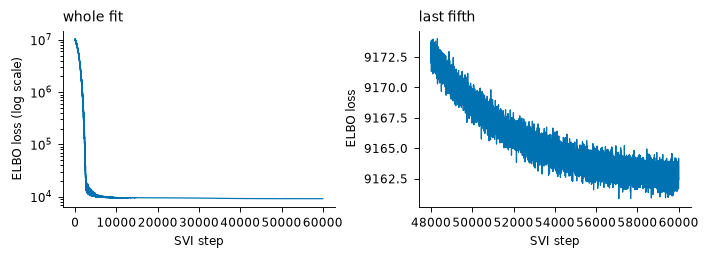

In [10]:
fig, (left, right) = plt.subplots(1, 2, figsize=(6.5, 2.4))
step = np.arange(1, len(fit.losses) + 1)
left.plot(step, fit.losses, color=BLUE, lw=0.8)
left.set_yscale("log")
left.set_xlabel("SVI step")
left.set_ylabel("ELBO loss (log scale)")
left.set_title("whole fit", loc="left")

tail = slice(int(0.8 * len(fit.losses)), None)
right.plot(step[tail], fit.losses[tail], color=BLUE, lw=0.8)
right.set_xlabel("SVI step")
right.set_ylabel("ELBO loss")
right.set_title("last fifth", loc="left")

fig.tight_layout()

## The ranking

At 3 µM, IKZF3 leads at 3.3% edited and ZNF827 follows at 2.8%.
By rank 15 the propensity is 1.2%, declining to 0.4% across the tail.
IKZF3 at the top is expected: it is the neosubstrate the class was defined on.

The nine domains in vermillion are those Sievers et al. (Science 362, eaat0572, 2018) called degraded on pomalidomide and that cloned successfully here; they named 11.
Six of the nine are in the top ten.

Across the library the fit puts 32 of 90 domains higher at 3 µM than at 300 nM, matching the raw reads.
Among the top fifteen it is 13.

In [11]:
# The 11 zinc-finger domains Sievers et al. call degraded on pomalidomide; 9 are in this
# library. Names are the truncated ones the screen's own tables use: ZN276 is ZNF276, ZN517
# is ZNF517, ZN582 is ZNF582, ZN653 is ZNF653, ZN654 is ZNF654, ZN787 is ZNF787, ZN827 is
# ZNF827.
SIEVERS_TARGETS = ["E4F1", "IKZF3", "ZN276", "ZN517", "ZN582",
                   "ZN653", "ZN654", "ZN787", "ZN827"]
TOP_N = 10

doses = high.merge(low[["gene", "propensity"]], on="gene", suffixes=("", "_low"))
rises = doses["propensity"] > doses["propensity_low"]
print(f"fitted propensity higher at 3 uM: {rises.sum()} of {len(doses)} domains")
print(f"among the top fifteen:            {rises.head(15).sum()} of 15")

fitted propensity higher at 3 uM: 32 of 90 domains
among the top fifteen:            13 of 15


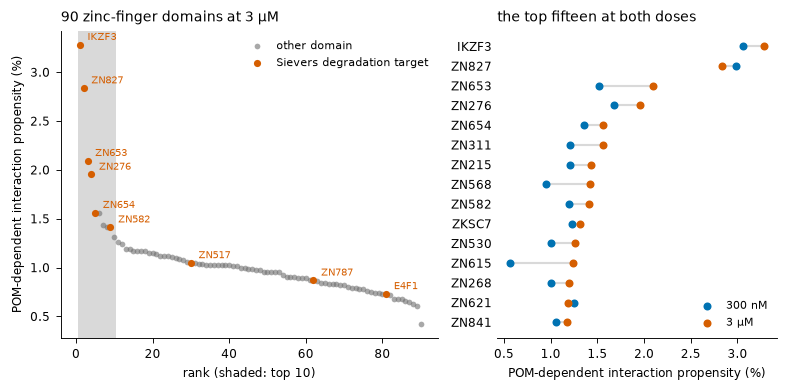

In [12]:
fig, (left, right) = plt.subplots(1, 2, figsize=(7.2, 3.6),
                                  gridspec_kw={"width_ratios": [1.35, 1]})

known = high["gene"].isin(SIEVERS_TARGETS)
left.axvspan(0.5, TOP_N + 0.5, color=PALE, lw=0, zorder=0)
left.scatter(high.loc[~known, "rank"], high.loc[~known, "propensity"] * 100,
             s=14, color=GREY, alpha=0.6, lw=0, label="other domain")
left.scatter(high.loc[known, "rank"], high.loc[known, "propensity"] * 100,
             s=22, color=VERMILLION, lw=0, label="Sievers degradation target")
for _, row in high[known].iterrows():
    left.annotate(row["gene"], (row["rank"], row["propensity"] * 100),
                  textcoords="offset points", xytext=(5, 3),
                  fontsize=6.5, color=VERMILLION)
left.set_xlabel(f"rank (shaded: top {TOP_N})")
left.set_ylabel("POM-dependent interaction propensity (%)")
left.set_title("90 zinc-finger domains at 3 µM", loc="left")
left.legend(loc="upper right", fontsize=7)

top = doses.head(15)
y = np.arange(len(top))[::-1]
right.hlines(y, top["propensity_low"] * 100, top["propensity"] * 100, color=PALE, lw=1.4)
right.scatter(top["propensity_low"] * 100, y, s=18, color=BLUE, label="300 nM", zorder=3)
right.scatter(top["propensity"] * 100, y, s=18, color=VERMILLION, label="3 µM", zorder=3)
right.set_yticks(y, top["gene"])
right.set_ylim(-0.8, len(top) - 0.2)
right.set_xlabel("POM-dependent interaction propensity (%)")
right.set_title("the top fifteen at both doses", loc="left")
right.tick_params(axis="y", length=0)
right.spines["left"].set_visible(False)
right.legend(loc="lower right", fontsize=7)

fig.tight_layout()

## Are the known targets enriched at the top?

Six of nine in the top ten needs a null: how often would ten domains drawn at random from 90 contain six or more of the nine known targets?
That is a hypergeometric upper tail, 90 in the urn, 9 marked, 10 drawn.

Ten is a chosen cut and the test knows nothing about how it was chosen.
The window was not fixed in advance, so this does not carry the guarantee a pre-registered cut would.

In [13]:
present = [gene for gene in SIEVERS_TARGETS if gene in set(high["gene"])]
top_genes = list(high["gene"].head(TOP_N))
overlap = [gene for gene in top_genes if gene in present]

p_enrichment = stats.hypergeom.sf(len(overlap) - 1, len(high), len(present), TOP_N)

print(f"library:  {len(high)} domains, {len(present)} of them known targets")
print(f"top {TOP_N}:   {', '.join(top_genes)}")
print(f"overlap:  {len(overlap)} known targets ({', '.join(overlap)})")
print(f"hypergeometric P = {p_enrichment:.3g}")

library:  90 domains, 9 of them known targets
top 10:   IKZF3, ZN827, ZN653, ZN276, ZN654, ZN311, ZN215, ZN568, ZN582, ZKSC7
overlap:  6 known targets (IKZF3, ZN827, ZN653, ZN276, ZN654, ZN582)
hypergeometric P = 2.5e-05


## Benchmarking against published degradation

Enrichment at the head uses nine labels.
The whole ranking can be compared against a continuous measurement, and two exist for these domains.
Sievers et al. report an average pomalidomide fold depletion of a zinc-finger-GFP reporter over 86 of the 90 domains.
Nguyen et al. 2024 report a depletion log2 fold change in a different reporter and cell system, over nine.

Both Spearman and Pearson are reported, because for Sievers they disagree and the disagreement is informative.

In [14]:
benchmarks = pd.read_csv(DATA / "annotations" / "degrader_benchmarks.csv")
merged = high.merge(benchmarks, on="gene", how="left")


def correlate(x, y):
    """Spearman and Pearson of two vectors, with the number of pairs."""
    spearman = stats.spearmanr(x, y)
    pearson = stats.pearsonr(x, y)
    return {"n": len(x),
            "rho": float(spearman.statistic), "rho_p": float(spearman.pvalue),
            "r": float(pearson.statistic), "r_p": float(pearson.pvalue)}


sievers_part = merged.dropna(subset=["sievers_pom_fold_depletion"])
nguyen_part = merged.dropna(subset=["nguyen_2024_l2fc_depletion"])
sievers = correlate(sievers_part["propensity"], sievers_part["sievers_pom_fold_depletion"])
nguyen = correlate(nguyen_part["propensity"], nguyen_part["nguyen_2024_l2fc_depletion"])

for name, result in (("Sievers", sievers), ("Nguyen", nguyen)):
    print(f"{name}: n = {result['n']:2d}  "
          f"Spearman rho = {result['rho']:.3f} (P = {result['rho_p']:.3g})  "
          f"Pearson r = {result['r']:.3f} (P = {result['r_p']:.3g})")

Sievers: n = 86  Spearman rho = 0.142 (P = 0.192)  Pearson r = 0.540 (P = 8.2e-08)
Nguyen: n =  9  Spearman rho = 0.700 (P = 0.0358)  Pearson r = 0.535 (P = 0.138)


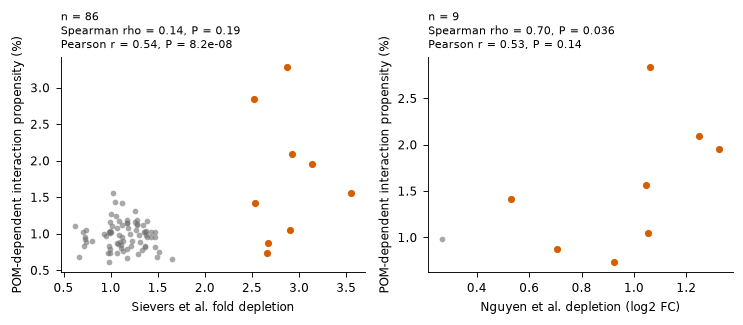

In [15]:
fig, (left, right) = plt.subplots(1, 2, figsize=(6.8, 3.0))

panels = [(left, "sievers_pom_fold_depletion", "Sievers et al. fold depletion", sievers),
          (right, "nguyen_2024_l2fc_depletion", "Nguyen et al. depletion (log2 FC)", nguyen)]
for ax, column, xlabel, result in panels:
    part = merged.dropna(subset=[column])
    known = part["gene"].isin(SIEVERS_TARGETS)
    ax.scatter(part.loc[~known, column], part.loc[~known, "propensity"] * 100,
               s=14, color=GREY, alpha=0.6, lw=0)
    ax.scatter(part.loc[known, column], part.loc[known, "propensity"] * 100,
               s=22, color=VERMILLION, lw=0)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("POM-dependent interaction propensity (%)")
    ax.set_title(f"n = {result['n']}\n"
                 f"Spearman rho = {result['rho']:.2f}, P = {result['rho_p']:.2g}\n"
                 f"Pearson r = {result['r']:.2f}, P = {result['r_p']:.2g}",
                 loc="left", fontsize=7.5)

fig.tight_layout()

### Why the two coefficients disagree for Sievers

Pearson r = 0.54 at P = 8e-08 and Spearman rho = 0.14 at P = 0.19 measure different things, and this dataset's shape makes the difference large.

The nine known targets lie between fold depletions of 2.52 and 3.55, every other domain between 0.62 and 1.65, with an empty gap between.
Inside the bulk of 77 the two measurements are unrelated, and inside the nine they are unrelated as well.
The signal is the separation between groups, which the propensity also picks up (targets above the rest, Mann-Whitney P = 0.003).
Pearson works on the values, so the distance between groups drives it.
Spearman replaces values by ranks, compressing that gap to one step and leaving the comparison resting on within-group orderings that carry no signal.

The screen separates the known targets from the library; it does not order degradation strength within either group.

For Nguyen the pattern reverses: Spearman rho = 0.70 at P = 0.036 over nine domains, Pearson r = 0.53 at P = 0.14.
Nine points is one weak result.

In [16]:
targets = sievers_part[sievers_part["gene"].isin(present)]
rest = sievers_part[~sievers_part["gene"].isin(present)]

print(f"Sievers fold depletion, targets:  {targets['sievers_pom_fold_depletion'].min():.2f} "
      f"to {targets['sievers_pom_fold_depletion'].max():.2f}  (n = {len(targets)})")
print(f"Sievers fold depletion, the rest: {rest['sievers_pom_fold_depletion'].min():.2f} "
      f"to {rest['sievers_pom_fold_depletion'].max():.2f}  (n = {len(rest)})")
print()

within_rest = correlate(rest["propensity"], rest["sievers_pom_fold_depletion"])
within_targets = correlate(targets["propensity"], targets["sievers_pom_fold_depletion"])
print(f"within the 77 non-targets: Spearman rho = {within_rest['rho']:.3f} "
      f"(P = {within_rest['rho_p']:.2f}), Pearson r = {within_rest['r']:.3f} "
      f"(P = {within_rest['r_p']:.2f})")
print(f"within the 9 targets:      Spearman rho = {within_targets['rho']:.3f} "
      f"(P = {within_targets['rho_p']:.2f})")
print()

separation = stats.mannwhitneyu(targets["propensity"], rest["propensity"],
                                alternative="greater")
auroc = separation.statistic / (len(targets) * len(rest))
print(f"targets against the rest on propensity: AUROC = {auroc:.3f}, "
      f"one-sided Mann-Whitney P = {separation.pvalue:.4f}")

Sievers fold depletion, targets:  2.52 to 3.55  (n = 9)
Sievers fold depletion, the rest: 0.62 to 1.65  (n = 77)

within the 77 non-targets: Spearman rho = -0.026 (P = 0.82), Pearson r = -0.057 (P = 0.62)
within the 9 targets:      Spearman rho = 0.117 (P = 0.77)

targets against the rest on propensity: AUROC = 0.782, one-sided Mann-Whitney P = 0.0030


## Reading the output

A screen with no untreated arm measures induced proximity.
Every number here is the editing propensity of CRBN and a domain in the presence of pomalidomide, and says nothing about that pair without the drug.
It is not an affinity and not a dissociation constant.
A domain ranking high has been brought near CRBN, which is a step toward degradation rather than a measurement of it.